In [1]:


import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


import kagglehub


/kaggle/input/datasets/adityakadiwal/water-potability/water_potability.csv


## Classificação de potabilidade de água utilizando MVS

## 1. Imports 

In [2]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, balanced_accuracy_score,
                             confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)

print("Bibliotecas importadas.")

Bibliotecas importadas.


## 2. Importação da base de dados

In [3]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/adityakadiwal/water-potability/water_potability.csv


In [4]:
df = pd.read_csv("/kaggle/input/datasets/adityakadiwal/water-potability/water_potability.csv")

print(f"Dados: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

Dados: 3276
Colunas: 10


## 3. Avaliação banco de dados

In [5]:
df.head(20)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
5,5.584087,188.313324,28748.687739,7.544869,326.678363,280.467916,8.399735,54.917862,2.559708,0
6,10.223862,248.071735,28749.716544,7.513408,393.663396,283.651634,13.789695,84.603556,2.672989,0
7,8.635849,203.361523,13672.091764,4.563009,303.309771,474.607645,12.363817,62.798309,4.401425,0
8,NaN,118.988579,14285.583854,7.804174,268.646941,389.375566,12.706049,53.928846,3.595017,0
9,11.180284,227.231469,25484.508491,9.077200,404.041635,563.885481,17.927806,71.976601,4.370562,0


In [6]:
df.tail(20)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
3256,7.607224,160.565253,39184.846720,7.826411,312.056066,503.158079,13.366994,62.022308,3.525027,1
3257,6.683368,272.111698,18989.316768,5.336202,336.555100,307.725009,20.178716,75.402260,5.208061,1
3258,6.638411,180.826667,9772.504814,8.295983,NaN,401.111143,12.601517,61.051889,5.164057,1
3259,9.271355,181.259617,16540.979048,7.022499,309.238865,487.692788,13.228441,NaN,4.333953,1
3260,NaN,134.736856,9000.025591,9.026293,NaN,428.213987,8.668672,74.773392,3.699558,1
3261,3.629922,244.187392,24856.633209,6.618071,366.967873,442.076337,13.302880,59.489294,4.754826,1
3262,8.378108,198.511213,28474.202580,6.477057,319.477187,499.866994,15.389083,35.221200,4.524693,1
3263,6.923636,260.593154,24792.525623,5.501164,332.232177,607.773567,15.483027,51.535867,4.013339,1
3264,5.893103,239.269481,20526.666156,6.349561,341.256362,403.617560,18.963707,63.846319,4.390702,1
3265,8.197353,203.105091,27701.794055,6.472914,328.886838,444.612724,14.250875,62.906205,3.361833,1


In [7]:
print ("Atributos da base:\n")
for i, col in enumerate(df.columns,1):
    print(f"{i:2d}. {col}")

Atributos da base:

 1. ph
 2. Hardness
 3. Solids
 4. Chloramines
 5. Sulfate
 6. Conductivity
 7. Organic_carbon
 8. Trihalomethanes
 9. Turbidity
10. Potability


### Descrição dos atributos

| Atributo | Descrição |
|---|---|
| ph | Potencial hidrogeniônico, indica acidez ou alcalinidade |
| Hardness | Dureza, concentração de sais de cálcio e magnésio, em mg/L |
| Solids | Sólidos dissolvidos totais, em ppm |
| Chloramines | Concentração de cloraminas, em ppm |
| Sulfate | Concentração de sulfato, em mg/L |
| Conductivity | Condutividade elétrica, em μS/cm |
| Organic_carbon | Carbono orgânico total, em ppm |
| Trihalomethanes | Concentração de trialometanos, em μg/L |
| Turbidity | Turbidez, medida da dispersão de luz pelas partículas em suspensão |
| **Potability** | **Variável alvo. 1 indica água própria para consumo, 0 imprópria** |



## 4 Verificação tipos de dados

In [8]:
print("Tipos de dados por coluna:")
print(df.dtypes)
print()

numericas = df.select_dtypes(include=[np.number]).columns.tolist()
nao_numericas = df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Colunas numéricas: {len(numericas)}")
print(f"Colunas não numéricas: {len(nao_numericas)}")




Tipos de dados por coluna:
ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64
dtype: object

Colunas numéricas: 10
Colunas não numéricas: 0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


## 5. Estatísticas descritivas

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.080795,1.594320,0.000000,6.093092,7.036752,8.062066,14.000000
Hardness,3276.0,196.369496,32.879761,47.432000,176.850538,196.967627,216.667456,323.124000
Solids,3276.0,22014.092526,8768.570828,320.942611,15666.690297,20927.833607,27332.762127,61227.196008
Chloramines,3276.0,7.122277,1.583085,0.352000,6.127421,7.130299,8.114887,13.127000
Sulfate,2495.0,333.775777,41.416840,129.000000,307.699498,333.073546,359.950170,481.030642
Conductivity,3276.0,426.205111,80.824064,181.483754,365.734414,421.884968,481.792304,753.342620
Organic_carbon,3276.0,14.284970,3.308162,2.200000,12.065801,14.218338,16.557652,28.300000
Trihalomethanes,3114.0,66.396293,16.175008,0.738000,55.844536,66.622485,77.337473,124.000000
Turbidity,3276.0,3.966786,0.780382,1.450000,3.439711,3.955028,4.500320,6.739000
Potability,3276.0,0.390110,0.487849,0.000000,0.000000,0.000000,1.000000,1.000000


In [11]:
escalas = df.describe().T[["min", "max", "mean", "std"]]
escalas["amplitude"] = escalas["max"] - escalas["min"]
escalas.sort_values("amplitude", ascending=False)

,min,max,mean,std,amplitude
Solids,320.942611,61227.196008,22014.092526,8768.570828,60906.253396
Conductivity,181.483754,753.342620,426.205111,80.824064,571.858866
Sulfate,129.000000,481.030642,333.775777,41.416840,352.030642
Hardness,47.432000,323.124000,196.369496,32.879761,275.692000
Trihalomethanes,0.738000,124.000000,66.396293,16.175008,123.262000
Organic_carbon,2.200000,28.300000,14.284970,3.308162,26.100000
ph,0.000000,14.000000,7.080795,1.594320,14.000000
Chloramines,0.352000,13.127000,7.122277,1.583085,12.775000
Turbidity,1.450000,6.739000,3.966786,0.780382,5.289000
Potability,0.000000,1.000000,0.390110,0.487849,1.000000



## 5.1. Análise dos dados 
Com a análise das medidas de tendência central e de dispersão, verificamos que as amplitudes dos atributos são bastante diferentes entre si. Enquanto o pH se concentra em uma faixa estreita, os sólidos dissolvidos totais alcançam a casa do milhão.

## 6. Distribuição da variável alvo

In [12]:
contagem = df["Potability"].value_counts().sort_index()
pct = df["Potability"].value_counts(normalize=True).sort_index() * 100

print("Distribuição da variável alvo:\n")
for c in contagem.index:
    rotulo = "Não potável" if c == 0 else "Potável"
    print(f"  {c} ({rotulo}): {contagem[c]} amostras, {pct[c]:.2f}%")

print(f"\nRazão entre classes: {contagem.max()/contagem.min():.2f}")

Distribuição da variável alvo:

  0 (Não potável): 1998 amostras, 60.99%
  1 (Potável): 1278 amostras, 39.01%

Razão entre classes: 1.56


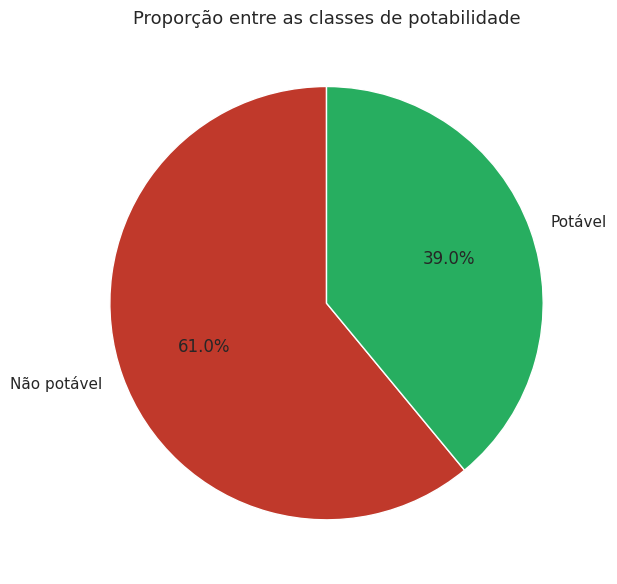

In [13]:
plt.figure(figsize=(7, 6))
plt.pie(contagem, labels=["Não potável", "Potável"], autopct="%1.1f%%",
        colors=["#c0392b", "#27ae60"], startangle=90)
plt.title("Proporção entre as classes de potabilidade", fontsize=13)
plt.tight_layout()
plt.show()

**Decisão metodológica, escolha das métricas.** Como vimos no gráfico acima, as classes estão desbalanceadas, com 61% de amostras não potáveis contra 39% de potáveis. Isso muda a forma de avaliar o modelo. Se um classificador simplesmente respondesse "não potável" para tudo, sem olhar nenhum atributo, ele já acertaria 61%. Ou seja, a acurácia sozinha não mostra se o modelo realmente aprendeu alguma coisa ou se está apenas repetindo a classe mais comum.
Por esse motivo, além da acurácia vamos acompanhar outras métricas:

- **Precisão:** das amostras que o modelo classificou como potáveis, quantas realmente eram
- **Revocação:** das amostras que eram potáveis de verdade, quantas o modelo conseguiu encontrar
- **F1-Score:** combina precisão e revocação em um único valor, usando média harmônica
- **Balanced Accuracy:** média do acerto em cada classe, sem ser influenciada pela classe majoritária

**Por que o F1 usa média harmônica e não aritmética.** A média aritmética permitiria que um valor alto compensasse um valor baixo. Um modelo com precisão de 0,95 e revocação de 0,05 teria média aritmética de 0,50, resultado que pareceria mediano quando na verdade o modelo é inútil, pois encontra apenas 5% dos casos que deveria encontrar.

A média harmônica é sempre puxada em direção ao menor dos dois valores. No mesmo exemplo, ela resultaria em 0,095, revelando o problema. Só quando precisão e revocação são próximas as duas médias coincidem.

Todas essas métricas serão calculadas futuramente, quando haver o treinamento final.

## 7. Validação de valores ausentes


In [14]:
tabela_nulos = pd.DataFrame({
    "valores_ausentes": df.isnull().sum(),
    "percentual": (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values("valores_ausentes", ascending=False)

print(tabela_nulos)
print(f"\nTotal de valores ausentes: {df.isnull().sum().sum()}")
print(f"Linhas com ao menos uma ausência: {df.isnull().any(axis=1).sum()}")
print(f"Linhas completas: {df.dropna().shape[0]} de {df.shape[0]}")
print(f"Linhas duplicadas: {df.duplicated().sum()}")

                 valores_ausentes  percentual
Sulfate                       781       23.84
ph                            491       14.99
Trihalomethanes               162        4.95
Hardness                        0        0.00
Chloramines                     0        0.00
Solids                          0        0.00
Conductivity                    0        0.00
Organic_carbon                  0        0.00
Turbidity                       0        0.00
Potability                      0        0.00

Total de valores ausentes: 1434
Linhas com ao menos uma ausência: 1265
Linhas completas: 2011 de 3276
Linhas duplicadas: 0


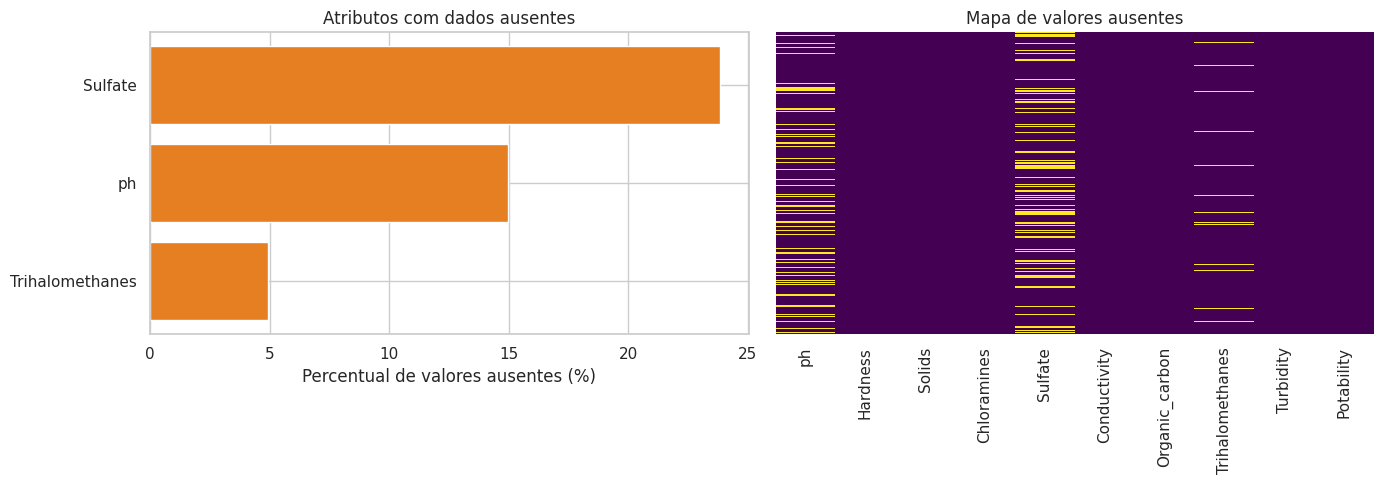

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

com_nulos = tabela_nulos[tabela_nulos["valores_ausentes"] > 0]
axes[0].barh(com_nulos.index, com_nulos["percentual"], color="#e67e22")
axes[0].set_xlabel("Percentual de valores ausentes (%)")
axes[0].set_title("Atributos com dados ausentes")
axes[0].invert_yaxis()

sns.heatmap(df.isnull(), cbar=False, cmap="viridis",
            yticklabels=False, ax=axes[1])
axes[1].set_title("Mapa de valores ausentes")

plt.tight_layout()
plt.show()

**Leitura dos resultados.** As ausências não estão distribuídas de forma uniforme pela base. Concentram-se em três atributos, com o sulfato sendo o mais afetado, seguido pelo pH e, em menor grau, pelos trialometanos. Os demais seis atributos estão completos. O mapa à direita mostra que as ausências ocorrem de forma dispersa ao longo dos registros, sem formar blocos ou padrão aparente. Sugerindo falhas pontuais de medição

## 8. Distribuição dos atributos

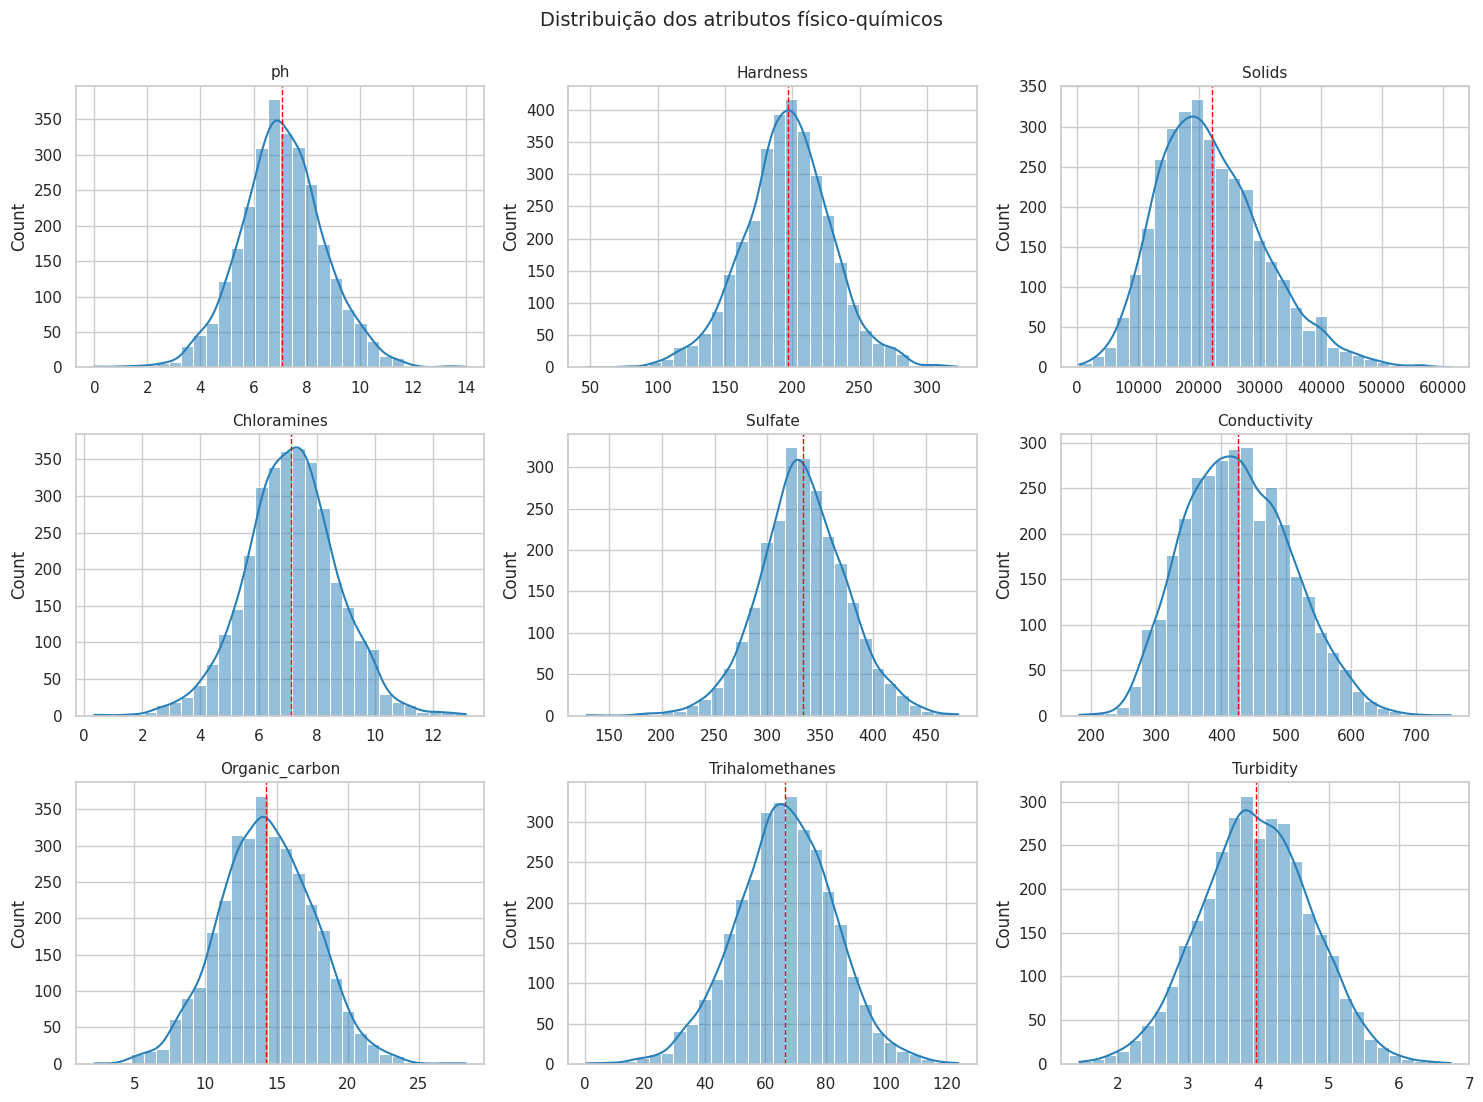

In [16]:
atributos = [c for c in df.columns if c != "Potability"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(atributos):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i],
                 color="#2980b9", bins=30)
    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel("")
    axes[i].axvline(df[col].mean(), color="red",
                    linestyle="--", linewidth=1)

plt.suptitle("Distribuição dos atributos físico-químicos",
             fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

**Leitura dos resultados.** Todos os atributos apresentam distribuição aproximadamente simétrica, com formato próximo ao da curva normal. Os valores concentram-se em torno do centro e decaem gradualmente para ambos os lados.

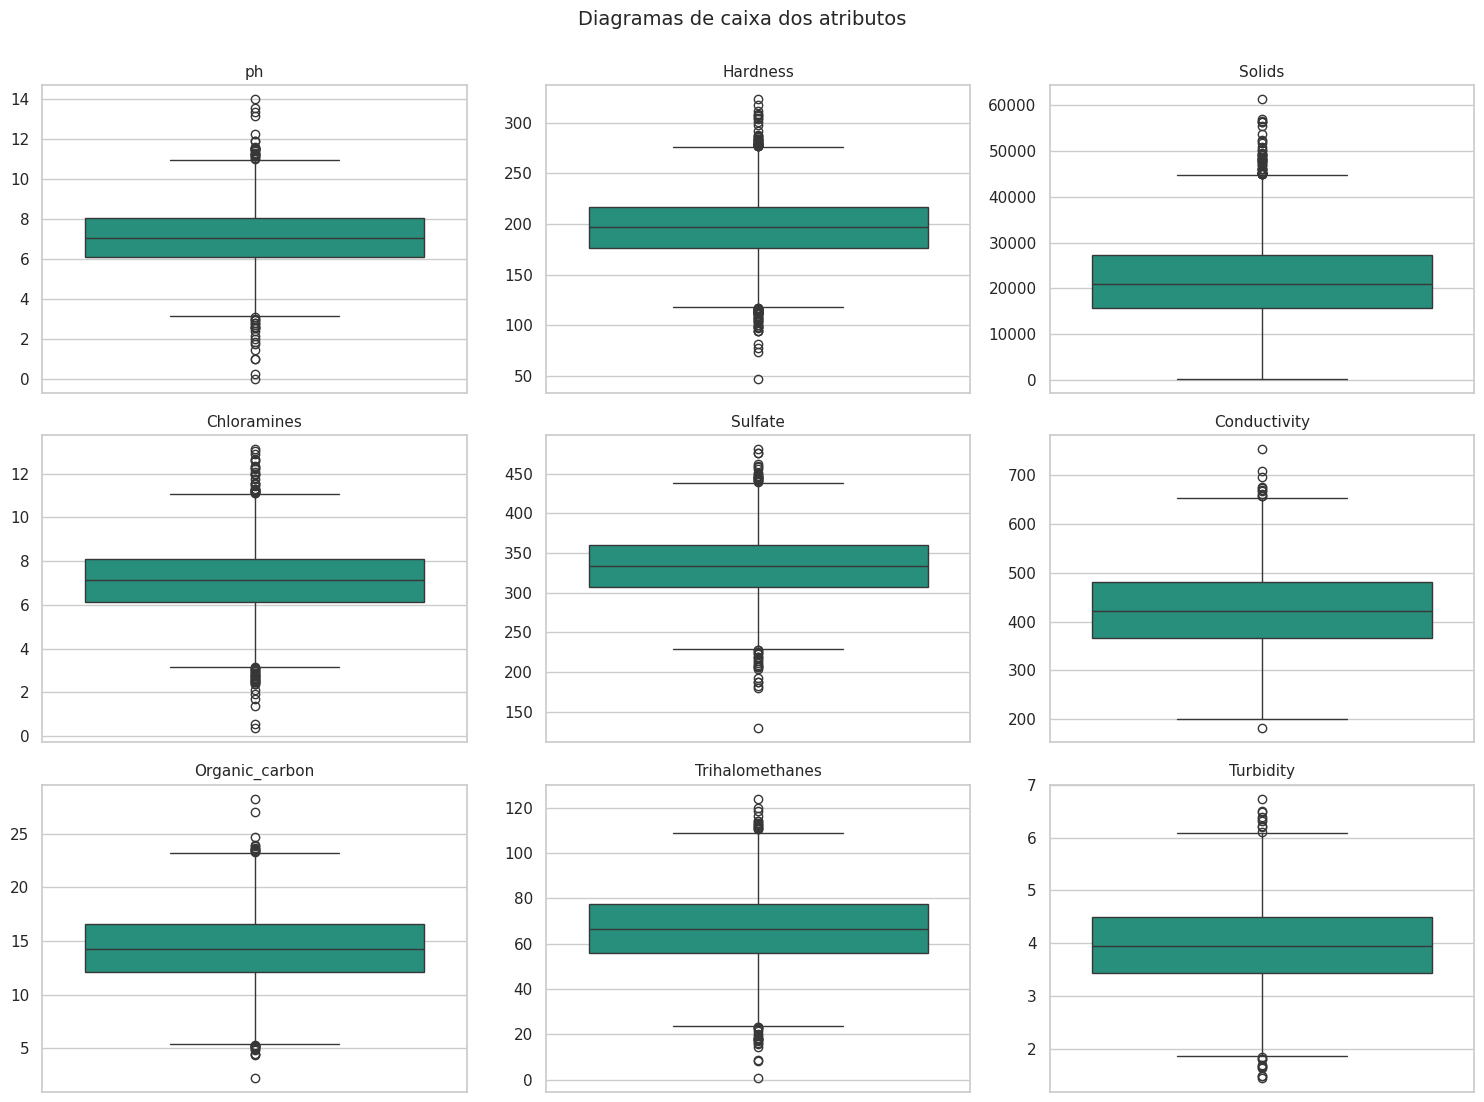

In [17]:
#atipicos

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(atributos):
    sns.boxplot(y=df[col], ax=axes[i], color="#16a085")
    axes[i].set_title(col, fontsize=11)
    axes[i].set_ylabel("")

plt.suptitle("Diagramas de caixa dos atributos", fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

**Leitura dos resultados.** Todos os atributos apresentam valores atípicos, visíveis como pontos além das hastes. A maioria distribui-se nas duas extremidades, o que é coerente com as distribuições simétricas observadas nos histogramas. O pH e as cloraminas concentram a maior quantidade de observações discrepantes, incluindo valores nas extremidades da escala. Os sólidos dissolvidos e o sulfato apresentam observações isoladas bastante afastadas do conjunto.


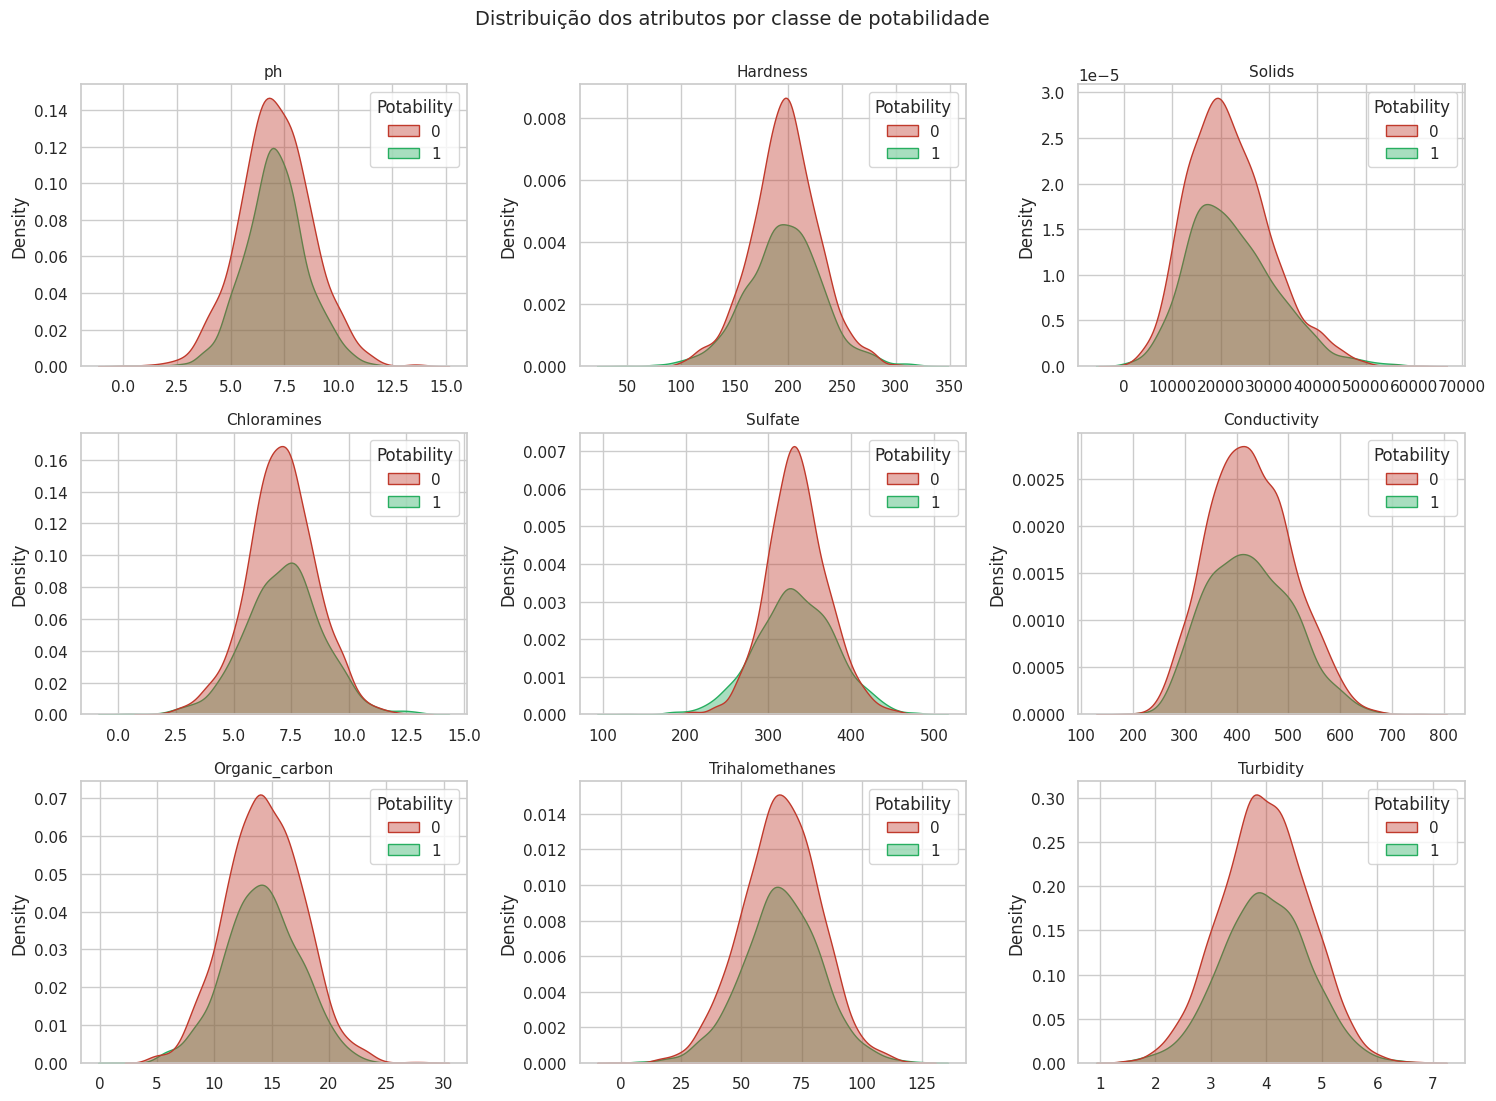

In [18]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(atributos):
    sns.kdeplot(data=df, x=col, hue="Potability", ax=axes[i],
                palette=["#c0392b", "#27ae60"], fill=True, alpha=0.4)
    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel("")

plt.suptitle("Distribuição dos atributos por classe de potabilidade",
             fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

**Leitura dos resultados.** Em todos os nove atributos, as curvas das duas classes ocupam praticamente a mesma faixa de valores, com centros coincidentes e formatos semelhantes. A diferença de altura entre elas reflete apenas o desbalanceamento da base, com mais amostras não potáveis, e não uma separação entre as categorias. Isso significa que nenhum parâmetro isolado distingue água potável de imprópria. Não existe faixa de pH, de dureza ou de sulfato que identifique uma classe, porque as duas ocupam os mesmos intervalos. Duas consequências decorrem daí. A primeira é que não há fronteira linear capaz de separar as classes, o que orienta a escolha do kernel.

## 9. Correlação



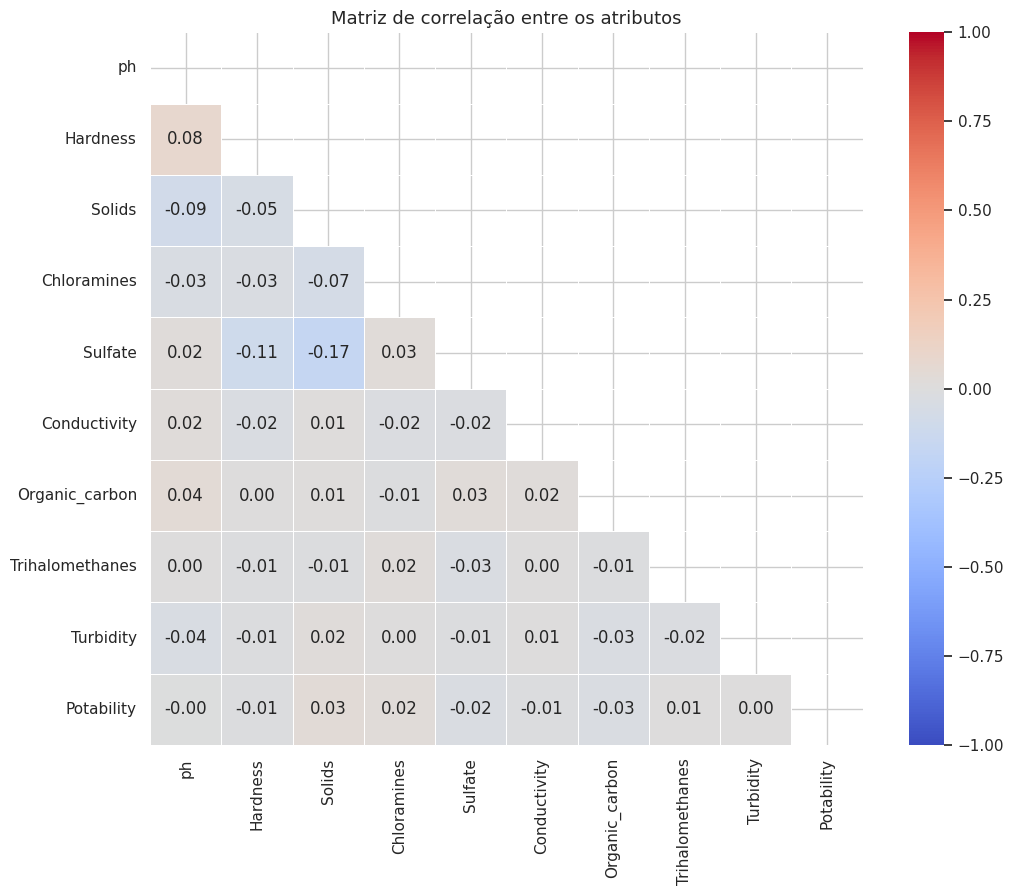

In [19]:
correlacao = df.corr()

plt.figure(figsize=(11, 9))
mascara = np.triu(np.ones_like(correlacao, dtype=bool))
sns.heatmap(correlacao, mask=mascara, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5)
plt.title("Matriz de correlação entre os atributos", fontsize=13)
plt.tight_layout()
plt.show()

**Leitura dos resultados.** A escala do gráfico foi fixada entre menos 1 e 1, que é o intervalo real do coeficiente de correlação. Com isso, a ausência de cor representa fielmente o que os dados mostram: todos os valores ficam entre menos 0,17 e 0,08, ou seja, muito próximos de zero.

**Relação com a variável alvo.** A última linha mostra a correlação de cada atributo com a potabilidade. O maior valor é 0,03, dos sólidos dissolvidos. Nenhum parâmetro, sozinho, tem relação linear com a classe. Isso confirma o que já tínhamos visto no gráfico de distribuição por classe.

**Relação entre atributos.** As maiores associações aparecem entre sulfato e sólidos dissolvidos, com menos 0,17, e entre sulfato e dureza, com menos 0,11. Continuam sendo fracas, mas fazem sentido, já que os três medem substâncias dissolvidas na água.

**Uma observação importante.** A correlação de Pearson mede apenas relação linear, ou seja, em linha reta. Se a relação entre um atributo e a classe fosse em curva, o coeficiente daria perto de zero mesmo assim. Por isso correlação baixa não encerra a análise, e é um dos motivos de usarmos o kernel RBF, que consegue capturar esse tipo de relação.

## 10. Dados ausentes

O tratamento prescrito para problemas situados no nível das linhas, envolvendo valores atípicos, consiste em limpeza estatística, imputação dos faltantes ou exclusão dos registros afetados.

Três estratégias são construídas e comparadas:

**A. Remover das linhas incompletas** — Utilizar somentes os valores originais, excluir os registros que não tem valor.

**B. Preencher com a mediana global** — mantém todos os registros, usando um único valor central por atributo, calculado com a base inteira.

**C. Preencher com a mediana por classe** — mantém todos os registros, mas calcula dois valores por atributo, um para as amostras potáveis e outro para as impróprias, e usa o valor do grupo ao qual a amostra pertence.

In [20]:
colunas_ausentes = [c for c in df.columns if df[c].isnull().sum() > 0]

print("ATRIBUTOS COM VALORES AUSENTES\n")
for col in colunas_ausentes:
    print(f"  {col}: {df[col].isnull().sum()} ausentes, "
          f"{df[col].isnull().sum()/len(df)*100:.2f}% da base")

ATRIBUTOS COM VALORES AUSENTES

  ph: 491 ausentes, 14.99% da base
  Sulfate: 781 ausentes, 23.84% da base
  Trihalomethanes: 162 ausentes, 4.95% da base


### Estratégia A, remoção das linhas incompletas

In [21]:
df_remocao = df.dropna()

perda = (df.shape[0] - df_remocao.shape[0]) / df.shape[0] * 100

print("ESTRATÉGIA A, REMOÇÃO")
print("=" * 55)
print(f"  Registros antes: {df.shape[0]}")
print(f"  Registros depois: {df_remocao.shape[0]}")
print(f"  Perda amostral: {perda:.1f}%")
print()
print("  Distribuição das classes:")
print(f"    base original: {(df['Potability'].value_counts(normalize=True)*100).round(2).to_dict()}")
print(f"    após remoção:  {(df_remocao['Potability'].value_counts(normalize=True)*100).round(2).to_dict()}")

ESTRATÉGIA A, REMOÇÃO
  Registros antes: 3276
  Registros depois: 2011
  Perda amostral: 38.6%

  Distribuição das classes:
    base original: {0: 60.99, 1: 39.01}
    após remoção:  {0: 59.67, 1: 40.33}


### Estratégias B e C, mediana global e mediana por classe


In [22]:
comparacao_medidas = []
for col in colunas_ausentes:
    med_por_classe = df.groupby("Potability")[col].median()
    comparacao_medidas.append({
        "atributo": col,
        "mediana_global": round(df[col].median(), 4),
        "mediana_nao_potavel": round(med_por_classe[0], 4),
        "mediana_potavel": round(med_por_classe[1], 4),
        "diferenca_entre_classes": round(abs(med_por_classe[1] - med_por_classe[0]), 4),
        "n_preenchidos": df[col].isnull().sum()
    })

pd.DataFrame(comparacao_medidas)

,atributo,mediana_global,mediana_nao_potavel,mediana_potavel,diferenca_entre_classes,n_preenchidos
0,ph,7.0368,7.0355,7.0368,0.0013,491
1,Sulfate,333.0735,333.3894,331.8382,1.5513,781
2,Trihalomethanes,66.6225,66.5422,66.6782,0.1360,162


In [23]:
df_global = df.copy()
df_por_classe = df.copy()

print("APLICAÇÃO DO PREENCHIMENTO\n")
for col in colunas_ausentes:
    df_global[col] = df_global[col].fillna(df[col].median())

    med_por_classe = df.groupby("Potability")[col].median()
    df_por_classe[col] = df_por_classe[col].fillna(
        df_por_classe["Potability"].map(med_por_classe)
    )

    print(f"  {col}: {df[col].isnull().sum()} valores preenchidos")

print(f"\nEstratégia B, ausentes restantes: {df_global.isnull().sum().sum()}")
print(f"Estratégia C, ausentes restantes: {df_por_classe.isnull().sum().sum()}")
print(f"Registros preservados em ambas: {df_global.shape[0]}, 100% da base")

APLICAÇÃO DO PREENCHIMENTO

  ph: 491 valores preenchidos
  Sulfate: 781 valores preenchidos
  Trihalomethanes: 162 valores preenchidos

Estratégia B, ausentes restantes: 0
Estratégia C, ausentes restantes: 0
Registros preservados em ambas: 3276, 100% da base


### Como cada estratégia afetou a distribuição

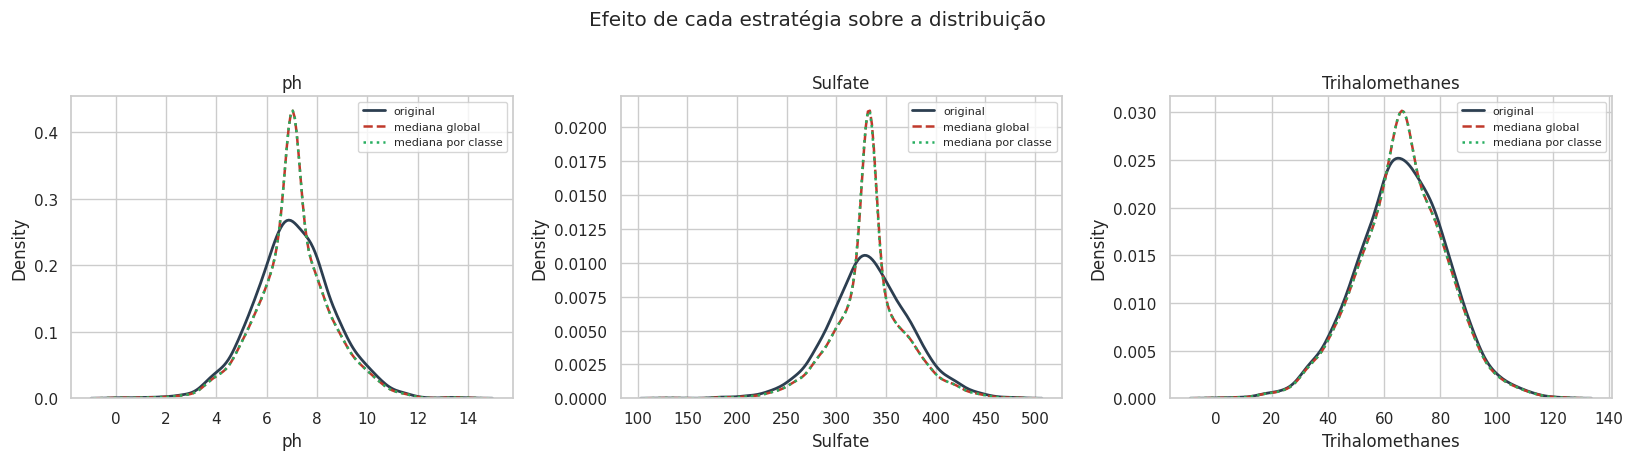

In [24]:
fig, axes = plt.subplots(1, len(colunas_ausentes),
                         figsize=(5.5*len(colunas_ausentes), 4.5))
if len(colunas_ausentes) == 1:
    axes = [axes]

for i, col in enumerate(colunas_ausentes):
    sns.kdeplot(df[col].dropna(), ax=axes[i], label="original",
                color="#2c3e50", linewidth=2)
    sns.kdeplot(df_global[col], ax=axes[i], label="mediana global",
                color="#c0392b", linewidth=1.8, linestyle="--")
    sns.kdeplot(df_por_classe[col], ax=axes[i], label="mediana por classe",
                color="#27ae60", linewidth=1.8, linestyle=":")
    axes[i].set_title(col)
    axes[i].legend(fontsize=8)

plt.suptitle("Efeito de cada estratégia sobre a distribuição", y=1.02)
plt.tight_layout()
plt.show()

**Decisão: preencher com a mediana por classe, estratégia C.**

**Por que não removemos as linhas.** Excluir os registros incompletos custaria 38,6% da base. Como as classes já são desbalanceadas, perder tantos registros prejudica principalmente a classe potável, que é a minoritária e justamente a que o modelo tem mais dificuldade de aprender. Quanto menos exemplos dela sobram, pior.

**Por que não usamos a média.** A média é puxada por valores muito altos ou muito baixos, e os boxplots mostraram que existem valores atípicos nos três atributos que precisam de imputação. A mediana não tem esse problema, porque é o valor que fica no meio quando os dados são ordenados, e não depende do tamanho dos extremos. Vale registrar, porém, que neste caso a diferença entre as duas medidas é pequena. No pH, média e mediana diferem em menos de 0,05. Isso indica que as distribuições, apesar dos outliers, são bastante simétricas, e que a escolha entre média e mediana dificilmente alteraria o resultado final. A mediana foi adotada por ser a opção mais segura diante de valores atípicos documentados.

**Por que separar por classe.** Usando uma mediana só para todos, qualquer diferença entre os dois grupos seria ignorada. Calculando separado, o valor preenchido acompanha o grupo da amostra.
**O custo dessa escolha.** Como mostra a tabela acima, as duas imputações diminuem o desvio padrão dos atributos tratados. Isso acontece porque inserir o mesmo valor centenas de vezes concentra os dados

In [25]:
df_tratado = df_por_classe.copy()

print("=" * 55)
print("RESUMO DA ETAPA DE PREPARAÇÃO DOS DADOS")
print("=" * 55)
print(f"Estratégia adotada: preenchimento pela mediana por classe")
print(f"Registros: {df_tratado.shape[0]}")
print(f"Atributos preditores: {df_tratado.shape[1]-1}")
print(f"Variável alvo: Potability, binária")
print(f"Valores ausentes: {df_tratado.isnull().sum().sum()}")
print(f"Atributos não numéricos: {len(df_tratado.select_dtypes(exclude=[np.number]).columns)}")
print(f"Registros duplicados: {df_tratado.duplicated().sum()}")
print("=" * 55)

df_tratado.head()

RESUMO DA ETAPA DE PREPARAÇÃO DOS DADOS
Estratégia adotada: preenchimento pela mediana por classe
Registros: 3276
Atributos preditores: 9
Variável alvo: Potability, binária
Valores ausentes: 0
Atributos não numéricos: 0
Registros duplicados: 0


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.035456,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,333.389426,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,333.389426,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


## 11. Separação entre atributos e variável alvo

In [26]:
X = df_tratado.drop(columns=["Potability"])
y = df_tratado["Potability"]

print(f"Matriz de atributos X: {X.shape}")
print(f"Vetor alvo y: {y.shape}")

Matriz de atributos X: (3276, 9)
Vetor alvo y: (3276,)


## 12. Divisão em treino e teste

**As decisões aqui:** dividimos 80% para treino e 20% para teste, que é a proporção mais usada. Aplicamos estratificação, para que a proporção entre as classes se mantenha nas duas partes, o que é necessário porque a base é desbalanceada. E fixamos a semente aleatória em 42, para que qualquer pessoa que rode o notebook obtenha exatamente a mesma divisão.

In [27]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("DIVISÃO DA BASE")
print("=" * 50)
print(f"Treino: {X_treino.shape[0]} registros")
print(f"Teste:  {X_teste.shape[0]} registros")
print()
print("Proporção de classes preservada:")
print(f"  original: {(y.value_counts(normalize=True)*100).round(2).to_dict()}")
print(f"  treino:   {(y_treino.value_counts(normalize=True)*100).round(2).to_dict()}")
print(f"  teste:    {(y_teste.value_counts(normalize=True)*100).round(2).to_dict()}")

DIVISÃO DA BASE
Treino: 2620 registros
Teste:  656 registros

Proporção de classes preservada:
  original: {0: 60.99, 1: 39.01}
  treino:   {0: 60.99, 1: 39.01}
  teste:    {0: 60.98, 1: 39.02}


## 13. Padronização dos atributos

Como ja vimos, as escalas dos atributos são muito diferentes entre si, o que prejudicaria o cálculo de distâncias do SVM. A padronização transforma cada atributo para média zero e desvio padrão 1, colocando todos na mesma escala.

**Uma decisão importante:** o transformador é ajustado apenas no conjunto de treino e depois aplicado ao de teste. Se calculássemos a média e o desvio sobre a base inteira, informação do teste entraria no pré-processamento e o teste deixaria de ser realmente inédito.

In [28]:
scaler = StandardScaler()
X_treino_norm = scaler.fit_transform(X_treino)
X_teste_norm = scaler.transform(X_teste)

pd.DataFrame({
    "media_antes": X_treino.mean().round(2),
    "desvio_antes": X_treino.std().round(2),
    "media_depois": X_treino_norm.mean(axis=0).round(4),
    "desvio_depois": X_treino_norm.std(axis=0).round(4)
})

,media_antes,desvio_antes,media_depois,desvio_depois
ph,7.08,1.47,0.0,1.0
Hardness,196.52,32.64,-0.0,1.0
Solids,21888.07,8760.11,0.0,1.0
Chloramines,7.12,1.60,0.0,1.0
Sulfate,333.71,36.24,0.0,1.0
Conductivity,427.92,80.94,0.0,1.0
Organic_carbon,14.27,3.30,-0.0,1.0
Trihalomethanes,66.17,15.80,0.0,1.0
Turbidity,3.97,0.78,-0.0,1.0


## 14. Linha de base e modelo de referência

A **linha de base trivial** é o que um classificador conseguiria chutando sempre a classe majoritária. Como ele não aprende nada, essa acurácia é o piso: qualquer resultado abaixo ou igual a isso significa que o modelo não aprendeu.

O **modelo de referência** é um SVM com os parâmetros padrão da biblioteca, sem ajuste nenhum. Ele serve para isolar o quanto o GridSearch realmente acrescentou.

In [29]:
classe_majoritaria = y_teste.value_counts(normalize=True).max()

print("LINHA DE BASE TRIVIAL")
print("=" * 50)
print(f"Chutando sempre a classe majoritária: {classe_majoritaria*100:.2f}%")

LINHA DE BASE TRIVIAL
Chutando sempre a classe majoritária: 60.98%


In [30]:
svm_base = SVC(random_state=42)
svm_base.fit(X_treino_norm, y_treino)

y_pred_base = svm_base.predict(X_teste_norm)
acc_base = accuracy_score(y_teste, y_pred_base)
f1_base = f1_score(y_teste, y_pred_base)

print("MODELO DE REFERÊNCIA, PARÂMETROS PADRÃO")
print("=" * 50)
print(f"Kernel: {svm_base.kernel} | C: {svm_base.C} | Gamma: {svm_base.gamma}")
print(f"Acurácia no teste: {acc_base*100:.2f}%")
print(f"F1-Score no teste: {f1_base:.4f}")
print(f"Ganho sobre a linha de base: {(acc_base-classe_majoritaria)*100:+.2f} pontos percentuais")

MODELO DE REFERÊNCIA, PARÂMETROS PADRÃO
Kernel: rbf | C: 1.0 | Gamma: scale
Acurácia no teste: 67.07%
F1-Score no teste: 0.3933
Ganho sobre a linha de base: +6.10 pontos percentuais


## 15. GridSearch

**O que vamos testar.** A busca considera os kernels RBF e polinomial, os dois capazes de construir fronteiras curvas. Essa escolha vem da análise anterior: como as duas classes ocupam praticamente a mesma faixa de valores em todos os atributos, dificilmente existe uma reta capaz de separá-las. Ainda assim, o kernel linear é avaliado logo em seguida para confirmar essa expectativa, usando uma implementação diferente, já que no SVC ele não convergiu.

**Qual critério usamos para escolher.** A busca precisa de uma métrica para decidir qual combinação é a melhor. Como vimos na seção 6, a acurácia não serve para isso em base desbalanceada, porque favorece a classe majoritária.

Usamos o F1-macro, que calcula o F1 de cada classe separadamente e tira a média. É diferente do F1 simples, que na configuração padrão considera apenas a classe positiva: com essa versão, um modelo que respondesse "potável" para quase tudo obteria pontuação alta sem ter capacidade real de classificar. O F1-macro evita esse comportamento, porque penaliza o mau desempenho em qualquer uma das classes.

**Como a busca é feita.** Validação cruzada estratificada com cinco partições, aplicada apenas sobre o treino. O conjunto de teste não é tocado nessa etapa, para que a avaliação final continue medindo o desempenho em dados realmente inédit

**Limite de iterações.** O parâmetro max_iter é definido para evitar que combinações extremas, com C e gamma altos, fiquem iterando indefinidamente sem convergir. Combinações que atingirem esse limite geram aviso e são consideradas com o resultado obtido até ali.

In [31]:
grade = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1, "scale"],
    "kernel": ["rbf", "poly"]
}

total = len(grade["C"]) * len(grade["gamma"]) * len(grade["kernel"])
print(f"Combinações a avaliar: {total}")
print(f"Total de treinamentos: {total * 5}")

Combinações a avaliar: 40
Total de treinamentos: 200


In [32]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=SVC(random_state=42, max_iter=200000),
    param_grid=grade,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid.fit(X_treino_norm, y_treino)

print("\nBusca concluída.")

Fitting 5 folds for each of 40 candidates, totalling 200 fits



Busca concluída.


In [33]:
print("RESULTADO DO GRIDSEARCH")
print("=" * 50)
print("Melhores hiperparâmetros encontrados:")
for parametro, valor in grid.best_params_.items():
    print(f"  {parametro}: {valor}")
print()
print(f"F1-macro médio na validação cruzada: {grid.best_score_:.4f}")

RESULTADO DO GRIDSEARCH
Melhores hiperparâmetros encontrados:
  C: 10
  gamma: scale
  kernel: rbf

F1-macro médio na validação cruzada: 0.6345


### Avaliação do kernel linear

O kernel linear é testado com o LinearSV.

In [34]:
grid_linear = GridSearchCV(
    estimator=LinearSVC(random_state=42, max_iter=10000, dual="auto"),
    param_grid={"C": [0.01, 0.1, 1, 10, 100]},
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid_linear.fit(X_treino_norm, y_treino)
y_pred_lin = grid_linear.best_estimator_.predict(X_teste_norm)

print("KERNEL LINEAR, via LinearSVC")
print("=" * 50)
print(f"Melhor C: {grid_linear.best_params_['C']}")
print(f"Acurácia no teste: {accuracy_score(y_teste, y_pred_lin)*100:.2f}%")
print(f"F1 da classe potável: {f1_score(y_teste, y_pred_lin):.4f}")
print(f"Revocação da classe potável: {recall_score(y_teste, y_pred_lin):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_teste, y_pred_lin)*100:.2f}%")

KERNEL LINEAR, via LinearSVC
Melhor C: 0.01
Acurácia no teste: 60.98%
F1 da classe potável: 0.0000
Revocação da classe potável: 0.0000
Balanced Accuracy: 50.00%


### Comparação entre os kernels

In [35]:
resultados = pd.DataFrame(grid.cv_results_)

print("DESEMPENHO POR KERNEL, média na validação cruzada\n")
print(resultados.groupby("param_kernel")["mean_test_score"].agg(["max", "mean"]).round(4))
print()

colunas = ["param_kernel", "param_C", "param_gamma",
           "mean_test_score", "std_test_score", "rank_test_score"]
resultados[colunas].sort_values("rank_test_score").head(10).reset_index(drop=True)

DESEMPENHO POR KERNEL, média na validação cruzada

                 max    mean
param_kernel                
poly          0.4808  0.4088
rbf           0.6345  0.4882



,param_kernel,param_C,param_gamma,mean_test_score,std_test_score,rank_test_score
0,rbf,10.0,scale,0.634479,0.020024,1
1,rbf,10.0,0.1,0.632018,0.016048,2
2,rbf,100.0,0.1,0.621309,0.016753,3
3,rbf,100.0,scale,0.618254,0.010718,4
4,rbf,1.0,scale,0.598398,0.017864,5
5,rbf,1.0,0.1,0.596965,0.020817,6
6,rbf,100.0,0.01,0.581677,0.027643,7
7,rbf,10.0,0.01,0.535439,0.027128,8
8,rbf,100.0,1,0.514184,0.017953,9
9,rbf,10.0,1,0.514184,0.017953,9


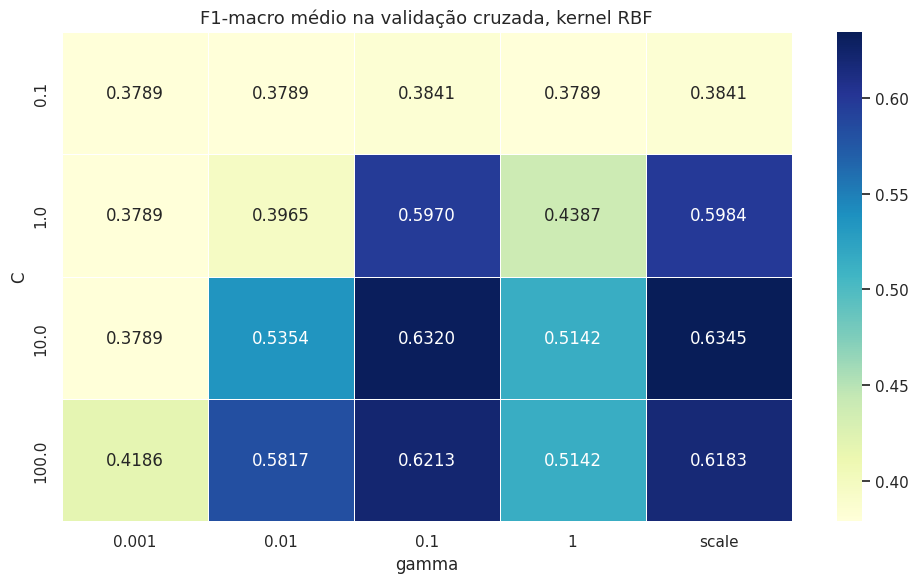

Diferença entre a melhor e a pior combinação: 0.2815


In [36]:
rbf = resultados[resultados["param_kernel"] == "rbf"].copy()
rbf["param_gamma"] = rbf["param_gamma"].astype(str)

pivot = rbf.pivot_table(index="param_C", columns="param_gamma",
                        values="mean_test_score")

plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="YlGnBu", linewidths=0.5)
plt.title("F1-macro médio na validação cruzada, kernel RBF", fontsize=13)
plt.xlabel("gamma")
plt.ylabel("C")
plt.tight_layout()
plt.show()

amplitude = resultados['mean_test_score'].max() - resultados['mean_test_score'].min()
print(f"Diferença entre a melhor e a pior combinação: {amplitude:.4f}")

**Leitura dos resultados.** O mapa mostra como o F1 varia conforme a combinação de C e gamma no kernel RBF. Valores extremos dos dois costumam piorar o resultado, porque deixam a fronteira rígida demais e o modelo passa a decorar o treino.

A tabela por kernel permite ver se algum deles se destaca, e a diferença entre a melhor e a pior combinação mostra o quanto o modelo é sensível ao ajuste. Se essa diferença for pequena, é sinal de que mexer nos parâmetros não muda muito o resultado.

**Leitura dos resultados.** O mapa mostra que valores altos de C e de gamma pioram o desempenho, o que faz sentido, já que os dois deixam a fronteira mais rígida e propensa a decorar o treino. A diferença pequena entre a melhor e a pior combinação indica que, neste problema, o modelo é pouco sensível ao ajuste dos parâmetros.

## 16. Modelo final e avaliação no teste


In [37]:
modelo_final = grid.best_estimator_
y_pred = modelo_final.predict(X_teste_norm)

acuracia = accuracy_score(y_teste, y_pred)
precisao = precision_score(y_teste, y_pred)
revocacao = recall_score(y_teste, y_pred)
f1 = f1_score(y_teste, y_pred)
f1_macro = f1_score(y_teste, y_pred, average="macro")
bal_acc = balanced_accuracy_score(y_teste, y_pred)

print("DESEMPENHO NO CONJUNTO DE TESTE")
print("=" * 50)
print(f"Acurácia:          {acuracia*100:.2f}%")
print(f"Balanced Accuracy: {bal_acc*100:.2f}%")
print(f"F1-macro:          {f1_macro:.4f}")
print()
print("Classe potável:")
print(f"  Precisão:  {precisao:.4f}")
print(f"  Revocação: {revocacao:.4f}")
print(f"  F1:        {f1:.4f}")
print()
print(f"Linha de base trivial: {classe_majoritaria*100:.2f}%")
print(f"Ganho sobre a linha de base: {(acuracia-classe_majoritaria)*100:+.2f} pontos percentuais")
print(f"Variação de acurácia sobre o modelo de referência: {(acuracia-acc_base)*100:+.2f} pontos percentuais")

DESEMPENHO NO CONJUNTO DE TESTE
Acurácia:          63.87%
Balanced Accuracy: 58.84%
F1-macro:          0.5855

Classe potável:
  Precisão:  0.5576
  Revocação: 0.3594
  F1:        0.4371

Linha de base trivial: 60.98%
Ganho sobre a linha de base: +2.90 pontos percentuais
Variação de acurácia sobre o modelo de referência: -3.20 pontos percentuais


In [38]:
print("RELATÓRIO DE CLASSIFICAÇÃO\n")
print(classification_report(y_teste, y_pred,
                            target_names=["Não potável", "Potável"],
                            digits=4))

RELATÓRIO DE CLASSIFICAÇÃO

              precision    recall  f1-score   support

 Não potável     0.6660    0.8175    0.7340       400
     Potável     0.5576    0.3594    0.4371       256

    accuracy                         0.6387       656
   macro avg     0.6118    0.5884    0.5855       656
weighted avg     0.6237    0.6387    0.6181       656



**Leitura dos resultados.** Comparar acurácia e Balanced Accuracy é o que revela o comportamento real do modelo. A acurácia conta o total de acertos, então é puxada pela classe majoritária. A Balanced Accuracy dá peso igual às duas classes, e por isso não é inflada pelo desbalanceamento.

## 17. Comparação entre as três estratégias de imputação (Remoção, Media, Mediana dos valores ausentes)

In [39]:
def avaliar_base(base, nome):
    Xb = base.drop(columns=["Potability"])
    yb = base["Potability"]

    Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
        Xb, yb, test_size=0.20, random_state=42, stratify=yb
    )

    sc = StandardScaler()
    Xb_tr_norm = sc.fit_transform(Xb_tr)
    Xb_te_norm = sc.transform(Xb_te)

    g = GridSearchCV(
        SVC(random_state=42, max_iter=200000),
        grade,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )
    g.fit(Xb_tr_norm, yb_tr)

    yb_pred = g.best_estimator_.predict(Xb_te_norm)

    return {
        "estratégia": nome,
        "registros": base.shape[0],
        "acurácia": round(accuracy_score(yb_te, yb_pred), 4),
        "bal_accuracy": round(balanced_accuracy_score(yb_te, yb_pred), 4),
        "f1_macro": round(f1_score(yb_te, yb_pred, average="macro"), 4),
        "precisão": round(precision_score(yb_te, yb_pred, zero_division=0), 4),
        "revocação": round(recall_score(yb_te, yb_pred), 4)
    }

comparacao = pd.DataFrame([
    avaliar_base(df_remocao, "A. Remoção das linhas"),
    avaliar_base(df_global, "B. Mediana global"),
    avaliar_base(df_por_classe, "C. Mediana por classe")
])

comparacao

,estratégia,registros,acurácia,bal_accuracy,f1_macro,precisão,revocação
0,A. Remoção das linhas,2011,0.6799,0.6515,0.6541,0.6308,0.5031
1,B. Mediana global,3276,0.6387,0.5884,0.5855,0.5576,0.3594
2,C. Mediana por classe,3276,0.6387,0.5884,0.5855,0.5576,0.3594


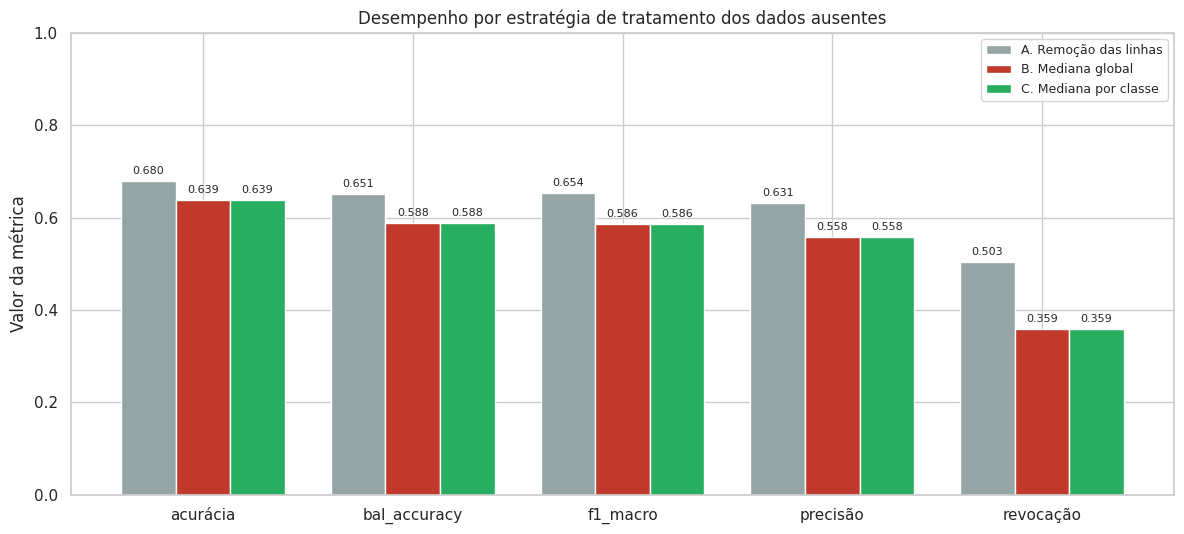

In [40]:
metricas = ["acurácia", "bal_accuracy", "f1_macro", "precisão", "revocação"]
x = np.arange(len(metricas))
largura = 0.26
cores = ["#95a5a6", "#c0392b", "#27ae60"]

plt.figure(figsize=(12, 5.5))
for i, linha in comparacao.iterrows():
    valores = [linha[m] for m in metricas]
    plt.bar(x + (i-1)*largura, valores, largura,
            label=linha["estratégia"], color=cores[i])
    for j, v in enumerate(valores):
        plt.text(j + (i-1)*largura, v + 0.015, f"{v:.3f}",
                 ha="center", fontsize=8)

plt.xticks(x, metricas)
plt.ylabel("Valor da métrica")
plt.title("Desempenho por estratégia de tratamento dos dados ausentes")
plt.ylim(0, 1)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

**Leitura dos resultados.** A base obtida por remoção tem um conjunto de teste bem menor, então suas métricas oscilam mais. Diferenças pequenas entre as estratégias B e C, os resultados tendem a ser parecidos, e isso já era esperado. A tabela de medianas dmostrou que os valores típicos das duas classes são muito próximos em cada atributo, então separar por classe quase não altera o que é preenchido.

## 18. Matriz de confusão

| Categoria | Significado |
|---|---|
| Verdadeiro negativo | Era imprópria, o modelo disse imprópria |
| Falso positivo | Era imprópria, o modelo disse potável |
| Falso negativo | Era potável, o modelo disse imprópria |
| Verdadeiro positivo | Era potável, o modelo disse potável |


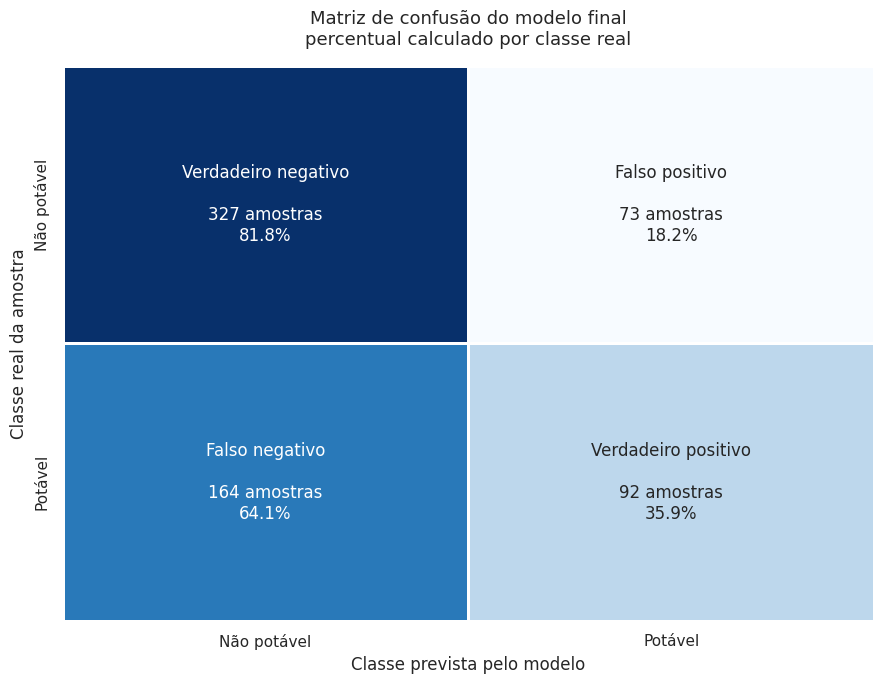

In [41]:
matriz = confusion_matrix(y_teste, y_pred)
matriz_pct = matriz.astype("float") / matriz.sum(axis=1)[:, np.newaxis] * 100

rotulos = np.array([
    ["Verdadeiro negativo", "Falso positivo"],
    ["Falso negativo", "Verdadeiro positivo"]
])

anotacoes = np.empty_like(matriz, dtype=object)
for i in range(2):
    for j in range(2):
        anotacoes[i, j] = f"{rotulos[i, j]}\n\n{matriz[i, j]} amostras\n{matriz_pct[i, j]:.1f}%"

plt.figure(figsize=(9, 7))
sns.heatmap(matriz_pct, annot=anotacoes, fmt="", cmap="Blues", cbar=False,
            xticklabels=["Não potável", "Potável"],
            yticklabels=["Não potável", "Potável"],
            annot_kws={"size": 12}, linewidths=2, linecolor="white")
plt.xlabel("Classe prevista pelo modelo", fontsize=12)
plt.ylabel("Classe real da amostra", fontsize=12)
plt.title("Matriz de confusão do modelo final\npercentual calculado por classe real",
          fontsize=13, pad=15)
plt.tight_layout()
plt.show()

In [42]:
vn, fp, fn, vp = matriz.ravel()

print("DETALHAMENTO DOS RESULTADOS")
print("=" * 55)
print(f"Verdadeiros negativos: {vn}")
print("  amostras impróprias classificadas corretamente")
print()
print(f"Falsos positivos: {fp}")
print("  amostras impróprias classificadas como potáveis")
print("  este é o erro mais grave do ponto de vista sanitário")
print()
print(f"Falsos negativos: {fn}")
print("  amostras potáveis classificadas como impróprias")
print()
print(f"Verdadeiros positivos: {vp}")
print("  amostras potáveis classificadas corretamente")
print("=" * 55)
print(f"\nTotal avaliado: {matriz.sum()} registros")
print(f"Acertos: {vn + vp} | Erros: {fp + fn}")

DETALHAMENTO DOS RESULTADOS
Verdadeiros negativos: 327
  amostras impróprias classificadas corretamente

Falsos positivos: 73
  amostras impróprias classificadas como potáveis
  este é o erro mais grave do ponto de vista sanitário

Falsos negativos: 164
  amostras potáveis classificadas como impróprias

Verdadeiros positivos: 92
  amostras potáveis classificadas corretamente

Total avaliado: 656 registros
Acertos: 419 | Erros: 237
